# 02. TVLA로 누설 위치 찾기

TVLA(Test Vector Leakage Assessment)는 두 입력군의 전력 분포가 같은지 확인하는 검사입니다. 여기서는 AES 키를 고정하고 평문이 항상 같은 그룹과 매번 바뀌는 그룹을 비교합니다. t-value가 큰 시간 구간에는 입력 데이터와 관련된 전력 차이가 있습니다. 이 검사는 누설 위치를 찾지만 키를 복구하지는 않습니다.

## fixed-vs-random 데이터 준비

고정 평문 300개와 무작위 평문 300개를 만들고 측정 순서를 섞습니다. `groups=0`은 고정 평문, `groups=1`은 무작위 평문입니다. 두 그룹의 개수가 같아야 평균과 분산을 공정하게 비교하기 쉽습니다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cw_sca_tutorial.analysis import welch_t_test
from cw_sca_tutorial.synthetic import make_tvla_dataset

dataset, groups = make_tvla_dataset(traces_per_group=300)
traces = dataset.traces
fixed = traces[groups == 0]
random = traces[groups == 1]
print(f"fixed={len(fixed)}, random={len(random)}, samples={traces.shape[1]}")

fixed=300, random=300, samples=700


## 두 그룹의 평균 파형

왼쪽에는 고정 평문군과 무작위 평문군의 평균을 겹쳐 그립니다. 두 선은 대부분 비슷해 보이지만 바이트가 처리되는 위치에서 작은 차이가 생깁니다. 오른쪽 heatmap에서는 고정 평문군이 위쪽, 무작위 평문군이 아래쪽에 놓입니다.

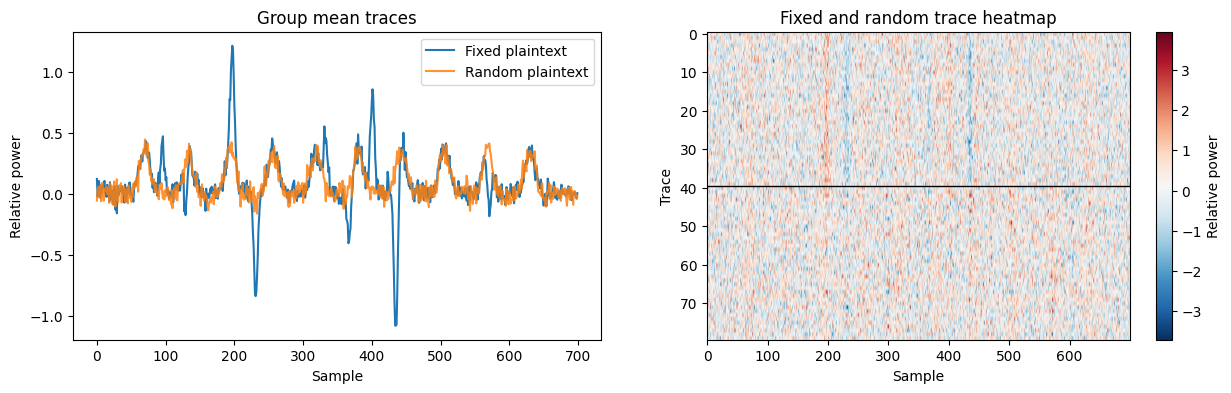

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(fixed.mean(axis=0), label="Fixed plaintext")
axes[0].plot(random.mean(axis=0), label="Random plaintext", alpha=.85)
axes[0].set(title="Group mean traces", xlabel="Sample", ylabel="Relative power")
axes[0].legend()
ordered = np.concatenate([fixed[:40], random[:40]])
image = axes[1].imshow(ordered, aspect="auto", cmap="RdBu_r")
axes[1].axhline(39.5, color="black", linewidth=1)
axes[1].set(title="Fixed and random trace heatmap", xlabel="Sample", ylabel="Trace")
fig.colorbar(image, ax=axes[1], label="Relative power")
plt.show()

## Welch t-test 계산

각 시간 샘플에서 두 그룹의 평균 차이를 표준오차로 나눕니다.

$$t = \frac{\bar{x}_{fixed}-\bar{x}_{random}}{\sqrt{s^2_{fixed}/n_{fixed}+s^2_{random}/n_{random}}}$$

그래프에는 수업에서 자주 쓰는 기준선 `±4.5`를 함께 표시합니다. 첫 50개 샘플은 누설을 넣지 않은 구간이므로 기준선을 넘지 않아야 합니다.

maximum |t|=17.39 at sample 436
wrong-window maximum |t|=3.80


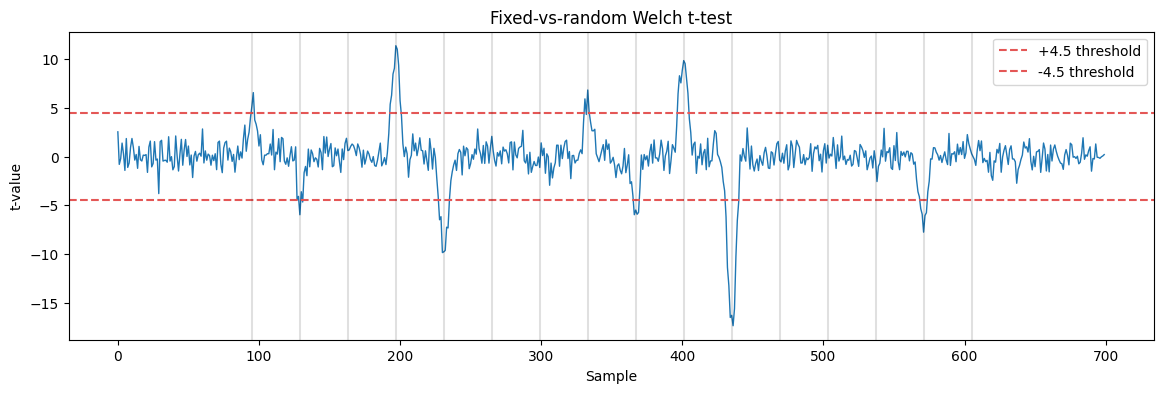

In [3]:
t_values = welch_t_test(traces, groups)
threshold = 4.5
peak = int(np.argmax(np.abs(t_values)))
print(f"maximum |t|={abs(t_values[peak]):.2f} at sample {peak}")
print(f"wrong-window maximum |t|={np.max(np.abs(t_values[:50])):.2f}")
assert np.max(np.abs(t_values)) > threshold
assert np.max(np.abs(t_values[:50])) < threshold

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(t_values, linewidth=1)
ax.axhline(threshold, color="#e45756", linestyle="--", label="+4.5 threshold")
ax.axhline(-threshold, color="#e45756", linestyle="--", label="-4.5 threshold")
for position in dataset.leakage_positions:
    ax.axvline(position, color="black", alpha=.12)
ax.set(title="Fixed-vs-random Welch t-test", xlabel="Sample", ylabel="t-value")
ax.legend()
plt.show()

## 파형 수에 따른 t-value

각 그룹에서 사용하는 파형 수를 늘리며 최대 `|t|`를 다시 계산합니다. 누설이 반복해서 나타나면 파형이 많아질수록 평균 차이의 통계적 신호가 커집니다.

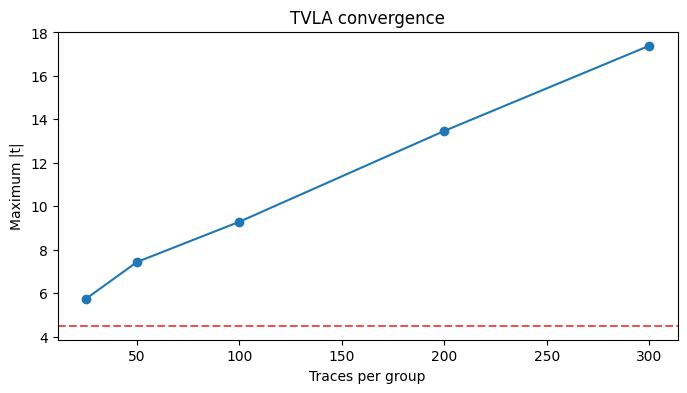

In [4]:
counts = [25, 50, 100, 200, 300]
max_t = []
for count in counts:
    subset = np.concatenate([np.flatnonzero(groups == 0)[:count], np.flatnonzero(groups == 1)[:count]])
    max_t.append(np.max(np.abs(welch_t_test(traces[subset], groups[subset]))))

plt.figure(figsize=(8, 4))
plt.plot(counts, max_t, "o-")
plt.axhline(4.5, color="#e45756", linestyle="--")
plt.xlabel("Traces per group")
plt.ylabel("Maximum |t|")
plt.title("TVLA convergence")
plt.show()